# 27 · 语义编码与向量检索

语义检索用共享编码器把查询和文档放进同一空间，再按向量相似度排序。本章具体检查token、mask pooling、归一化、截断和真实查询差异。

**先预测**：向量归一化之后点积与余弦还会不同吗？通用模型是否一定比BM25更懂生物医学？

复用正式run的5,183×384文档向量，不重复训练神经模型。新计算40个测试查询向量作诊断，原全部300查询的汇总结果仍独立保留。这是已见测试的探索分析，不是全新盲测。

**学习导航：** [上一章](26_Search_BM25.ipynb) · [下一章](28_Search_ANN.ipynb) · [综合实验](17_Search_Experiments.ipynb)

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'reclab').exists(): root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.search_lessons import context, query_vectors, score_query, labels
from reclab.search import BM25, rrf
from reclab.retrieval import topk, metrics
ctx = context()
print('Shared search run:', ctx['receipt']['run_id'])

Shared search run: 20261030T124927-d1467622


## 1. 从字符串到张量

tokenizer输出`input_ids`与`attention_mask`，形状均为batch×tokens。隐藏层为batch×tokens×384。池化时只平均mask=1的位置，再L2归一化；不能把padding当正文平均。

下面只打印形状和token数量，不保存原始查询文本。

In [2]:
from reclab.search_lessons import models
m=models(); qids=sorted(ctx['truth']['test'])[:40]
encoded=m.tokenizer([ctx['queries'][q] for q in qids[:2]],padding=True,truncation=True,max_length=256,return_tensors='pt')
print({k:tuple(v.shape) for k,v in encoded.items()})
print('nonpadding lengths:',encoded['attention_mask'].sum(1).tolist())
with m.torch.inference_mode():
    hidden=m.encoder(**encoded).last_hidden_state
    mask=encoded['attention_mask'].unsqueeze(-1)
    manual=m.torch.nn.functional.normalize((hidden*mask).sum(1)/mask.sum(1),dim=1).numpy()
actual=m.encode([ctx['queries'][q] for q in qids[:2]])
assert np.allclose(manual,actual,atol=1e-5)
print('hidden / pooled:',tuple(hidden.shape),actual.shape)

/Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'input_ids': (2, 17), 'token_type_ids': (2, 17), 'attention_mask': (2, 17)}
nonpadding lengths: [15, 17]
hidden / pooled: (2, 17, 384) (2, 384)


## 2. 归一化的几何含义

单位向量之间，`||x-y||²=2-2x·y`。因此最大点积、最大余弦、最小欧氏距离给出同一排序（并列时使用同一稳定规则）。若不归一化，向量长度可能主导得分；不能随意把不同度量混用。

In [3]:
vectors=ctx['vectors']; qv=query_vectors(qids)
assert np.allclose(np.linalg.norm(vectors,axis=1),1,atol=1e-5)
assert np.allclose(np.linalg.norm(qv,axis=1),1,atol=1e-5)
dot=vectors@qv[0]; distances=((vectors-qv[0])**2).sum(1)
assert np.allclose(distances,2-2*dot,atol=1e-5)
assert topk(np.r_[-np.inf,dot],10)==topk(np.r_[-np.inf,-distances],10)
print('normalized corpus shape:',vectors.shape,'float32 vector MiB:',vectors.nbytes/2**20)

normalized corpus shape: (5183, 384) float32 vector MiB: 7.59228515625


## 3. 截断把哪些信息丢掉了

正式配置标题+摘要最多256 wordpieces；模型支持的上限不等于实验实际使用长度。仅在前80文档上统计完整token长度，再把相同文档的推理长度从64变为256，观察向量差异。后一个实验只说明表示变化，不声称质量改善。

In [4]:
texts=ctx['texts'][:80]
lengths=np.array([len(m.tokenizer(t,add_special_tokens=True,truncation=False)['input_ids']) for t in texts])
print('80-doc sample token percentiles:',np.percentile(lengths,[50,90,100]),'fraction >256:',(lengths>256).mean())
from dataclasses import replace
old=m.config
try:
    m.config=replace(old,max_length=64); short=m.encode(texts[:8])
finally: m.config=old
full=m.encode(texts[:8])
display(pd.DataFrame({'doc_offset':range(8),'cosine_64_vs_256':(short*full).sum(1),'full_token_count':lengths[:8]}))

Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


80-doc sample token percentiles: [301.  532.7 975. ] fraction >256: 0.6


,doc_offset,cosine_64_vs_256,full_token_count
0,0,0.781264,409
1,1,0.915053,234
2,2,0.816750,175
3,3,0.850522,295
4,4,0.862596,223
5,5,0.904354,372
6,6,0.889317,209
7,7,0.843466,238


## 4. 同一查询上的词法与语义差异

保持40查询、语料和指标完全一致，只切换检索通道。输出每查询差值和平均值；不要把单个获胜例子当作普遍规律。冻结MiniLM预训练可能含相关科学材料，不能声称严格无污染评测。

,qid,bm25,dense,delta
7,1024,1.000000,0.00000,-1.000000
1,100,1.000000,0.50000,-0.500000
18,1107,1.000000,0.50000,-0.500000
34,1180,0.386853,0.00000,-0.386853
35,1185,1.000000,0.63093,-0.369070
33,118,1.000000,0.63093,-0.369070


,40-query diagnostic mean
bm25,0.680418
dense,0.643972
delta,-0.036446


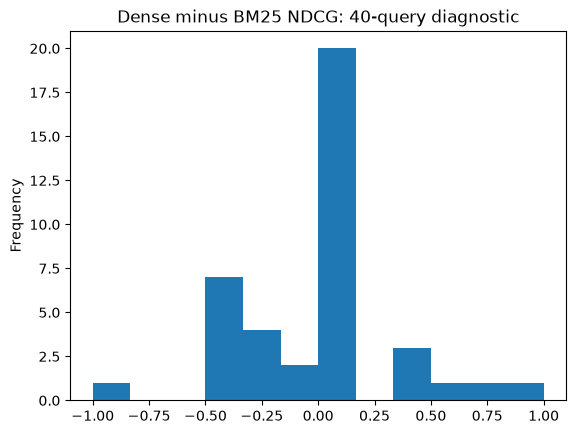

In [5]:
rows=[]
for q,v in zip(qids,qv):
    bm,ds,_=score_query(q,v)
    a=metrics({q:topk(bm,10)},labels([q]),10)['ndcg@10']
    b=metrics({q:topk(ds,10)},labels([q]),10)['ndcg@10']
    rows.append({'qid':q,'bm25':a,'dense':b,'delta':b-a})
comparison=pd.DataFrame(rows)
display(comparison.sort_values('delta').head(6))
display(comparison[['bm25','dense','delta']].mean().to_frame('40-query diagnostic mean'))
comparison.delta.plot.hist(bins=12,title='Dense minus BM25 NDCG: 40-query diagnostic');plt.show()

## 5. 离线成本与在线成本

文档编码可离线复用，查询编码每个新查询都需要运行。5,183×384 float32仅约7.6MiB，但模型加载、tokenization和编码仍有成本。正式延迟表包含查询编码；下一章只测索引阶段时会明确排除它，避免错误横比。

**练习**：将诊断查询集合改为训练集的固定40条，重跑第4节；只改查询集合，别同时换模型和参数。解释为什么通用语义模型可能在专业术语上输给BM25。